---
title: Australian Synoptic Weather Types
authors:
  - michael_barnes
  - frans_liqui_lung
  - christian_jakob
  - andrew_gunn
  - michael_reeder
downloads:
  - file: ./synoptic-weather-types.zip
    title: Download this recipe (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/synoptic-weather-types/swt.jpeg?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-synoptic-weather-types)	­

# Introduction

The Australian Synoptic Weather Types (SWTs) are set of 30 distinct circulation patterns over the Australian continent that characterise the weather over Australia. The dataset is generated from ERA5 reanalysis data by k-means clustering the 12z 850hPa wind field, producing a daily characterisation of the continent-wide circulation. [Barnes et. al 2025]( https://doi.org/10.1029/2025JD043873) describes the synoptic weather types and their characteristics in more detail.

```{figure} swt.jpeg
:alt: fishy
:align: center

Mean sea level pressure (black contours at 4 hPa intervals, vertically integrated water vapour greater than 48 $kg/m^2$ (green shading) and wind speed greater than 20$m/s$ (blue shading), 315 K (solid magenta) and 330 K (dashed magenta) 2 potential vorticity unit (PVU, 1 PVU = $10^{-6} m^2 s^{-1}K kg^{-1}$) contour. Closed lows (blue L) and highs (red H) in the mean sea level pressure field are also shown.
```

This notebook provides an overview of the tools and usage of the SWTs, including opening and using the climatology and some basic plotting tools and use cases. Most notably, one can assign any 850hPa gridded wind field to a SWT, allowing users to use the SWT framework in most gridded model datasets. The full set of tools is provided and continually updated in the [Australian Synoptic Weather Types](https://github.com/21centuryweather/Australian-synoptic-weather-types) repository.

In [1]:
import os
from datetime import datetime

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import xarray as xr
from cartopy.feature import LAND
from swt_assign import assign_grid_to_SWT
from swt_plotting import SWTcolors, plot_synoptic_PVless_ERA5

import warnings
warnings.filterwarnings("ignore")

# Datasets

Open the climatology of SWTs. The data is stored both in a netcdf and csv format called `SWT_climatology.nc` or `SWT_climatology.csv`. Includes daily SWTs from January 1952 to April 2026 and is based on the ERA5 850hPa u and v wind fields. Previous versions of this climatology are additionally available in the [Australian Synoptic Weather Types](https://github.com/21centuryweather/Australian-synoptic-weather-types) repository.

In [2]:
SWT_climatology = xr.open_dataset("data/SWT_climatology.nc")
SWT_climatology

<xarray.Dataset> Size: 761kB
Dimensions:       (time: 27149, SWTs: 30)
Coordinates:
  * time          (time) datetime64[ns] 217kB 1952-01-01T12:00:00 ... 2026-04...
  * SWTs          (SWTs) <U5 600B 'WH-A' 'WH-B' 'WH-C' ... 'AM-C' 'AM-D' 'AM-E'
Data variables:
    assigned_SWT  (time) <U5 543kB ...
Attributes:
    dataset:       Australian Synoptic Weather Types
    data source:   ERA5
    input data:    u-wind and v-wind on 850hPa
    last updated:  2026-08-27 15:31:32
    start month:   1952/01
    end month:     2026/04
    reference:     10.22541/essoar.174250748.85665142/v1
    created by:    Michael A. Barnes (ARC Centre of Excellence for 21st Centu...

Open the SWT dataset. This dataset comprises of the original set of 30 SWTs as described in [Barnes et. al 2025]( https://doi.org/10.1029/2025JD043873) together with the wind centroids required in order to assign a grid to a SWT.
The data is stored as netcdf called `SWT_data.nc`.

In [3]:
SWT_data = xr.open_dataset("data/SWT_data.nc")
SWT_data

<xarray.Dataset> Size: 1MB
Dimensions:       (time: 26298, SWT: 30, latitude: 31, longitude: 44)
Coordinates:
  * time          (time) datetime64[ns] 210kB 1952-01-01T12:00:00 ... 2023-12...
  * SWT           (SWT) <U5 600B 'WH-A' 'WH-B' 'WH-C' ... 'AM-C' 'AM-D' 'AM-E'
  * latitude      (latitude) float32 124B -5.0 -6.5 -8.0 ... -47.0 -48.5 -50.0
  * longitude     (longitude) float32 176B 100.0 101.5 103.0 ... 163.0 164.5
Data variables:
    assigned_SWT  (time) <U5 526kB ...
    clusterU      (SWT, latitude, longitude) float32 164kB ...
    clusterV      (SWT, latitude, longitude) float32 164kB ...

# Handling the SWT dataset

Plot a synoptic composite from ERA5 together with the relevant SWT code for 01/09/2025. Various plotting options are available within the [Australian Synoptic Weather Types](https://github.com/21centuryweather/Australian-synoptic-weather-types) repository!

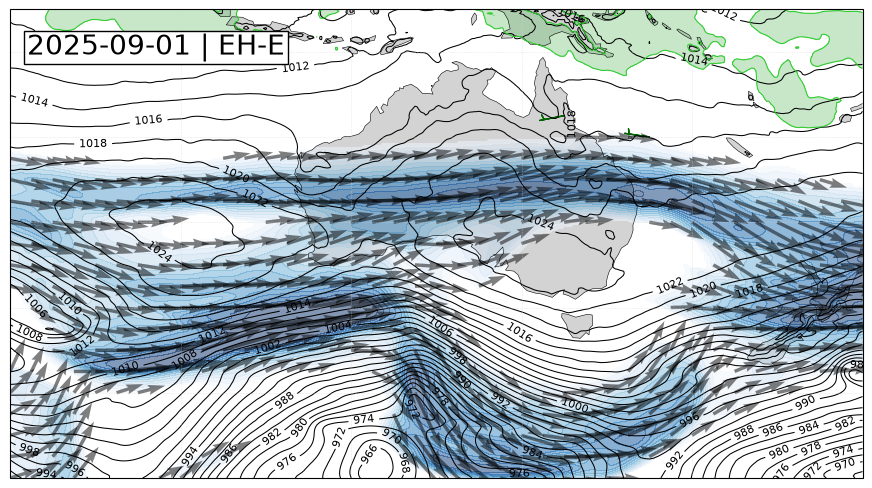

In [6]:
indt = datetime(2025, 9, 1, 12)
indt_SWT = SWT_climatology.sel(time=indt).assigned_SWT.item()
plot_synoptic_PVless_ERA5(indt_SWT, indt)

```{note}
The available ERA5 data includes daily (at 12z) 850hPa wind fields, mean sea level pressure, and total column water vapor. You can change the date to try to analyze the synoptic conditions associated with other SWTs.
```

### Seasonal distribution of SWTs

Here we will plot the running mean seasonal distribution of the SWTs centred on the summer months to show how the SWTs change seasonally. We will use the `SWT_climatology.nc` dataset.

In [ ]:
inrundays = 15  # Days to use for the running mean

SWT_climatology = SWT_climatology.sel(time=slice(datetime(1900, 1, 1), datetime(2025, 1, 1, 0)))
SWTnames = SWT_climatology.SWTs  # Get the names of the 30 synoptic types in teh typical order

cluster_series = (
    SWT_climatology.assigned_SWT
)  # Get the assigned daily SWT codes in the climatology

cluster_series.coords["mmdd"] = cluster_series["time"].dt.strftime(
    "%m%d"
)  # Get the day-month

grouped = cluster_series.groupby("mmdd")  # Group by the day and month

mmdds = list(grouped.groups.keys())
mmdds.remove("0229")  # Remove the extra leap year dates


def periodic_rolling_sum_centered(arr, window):
    arr = np.asarray(arr)

    pad = window // 2

    padded = np.pad(arr, (pad, pad), mode="wrap")

    kernel = np.ones(window, dtype=arr.dtype)
    out = np.convolve(padded, kernel, mode="valid")

    # If window is even, trim to original length
    return out[: len(arr)]

We need to reorder and reorganise the data to prepare for plotting the climatology centered in the summer months.

In [ ]:
reorder_st = np.where(np.array(mmdds) == "0801")[0][0]
mmdds = mmdds[reorder_st::] + mmdds[0:reorder_st]

cluster_labels = np.zeros((len(set(SWT_climatology.time.dt.year.values)), len(mmdds)))
cluster_spread = np.zeros((len(SWTnames), len(mmdds)))
for i, mmdd in enumerate(mmdds):
    selected_group = grouped.groups[mmdd]
    temp = cluster_series.isel(time=selected_group)
    cluster_labels[:, i] = xr.DataArray(
        pd.Categorical(temp.values, categories=SWTnames).codes,
        coords=temp.coords,
        dims=temp.dims,
        name="assigned_SWT_index",
    )

for it, t in enumerate(range(cluster_labels.shape[1])):
    for im, m in enumerate(range(cluster_labels.shape[0])):
        SWTindex = int(cluster_labels[im, it])
        cluster_spread[SWTindex, it] = cluster_spread[SWTindex, it] + 1

for im in range(cluster_spread.shape[0]):
    cluster_spread[im, :] = periodic_rolling_sum_centered(
        cluster_spread[im, :], inrundays
    )

cluster_spread_freq = cluster_spread / (
    inrundays * len(set(SWT_climatology.time.dt.year.values))
)

datetimes = [datetime.strptime(mmdd, "%m%d") for mmdd in mmdds]
month_ticks = [i for i, date in enumerate(datetimes) if date.day == 1]
month_ticklabels = [datetimes[m].strftime("%b") for m in month_ticks]

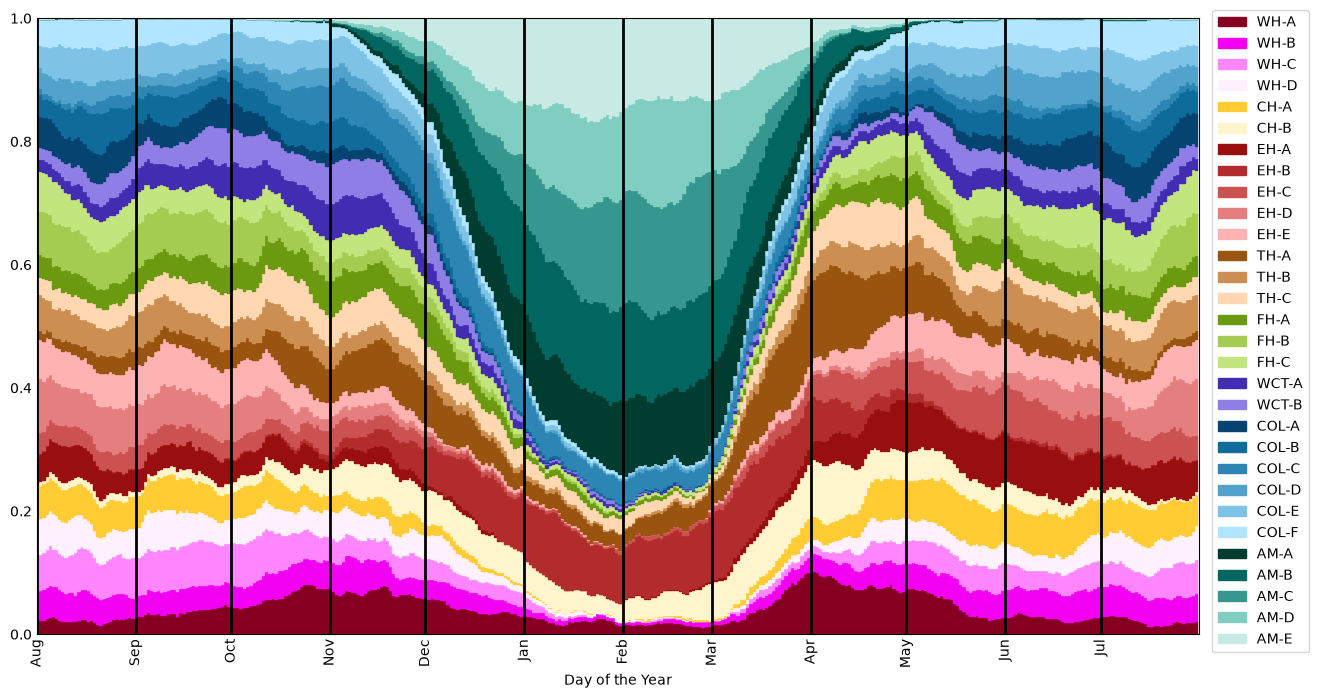

In [ ]:
# Plot the seasonal distribution climatology as a timeseries

fig, ax = plt.subplots(figsize=(15, 8))

# Number of bars (columns)
num_bars = cluster_spread_freq.shape[1]
x = np.arange(num_bars)
bottom = np.zeros(num_bars)

regticks = [4, 6, 11, 14, 17, 19, 25]
for i, (row, color) in enumerate(zip(cluster_spread_freq, SWTcolors)):
    # Draw the bar
    bars = plt.bar(
        x,
        row,
        bottom=bottom,
        color=color,
        label=SWTnames.values[i],
        edgecolor=color,  # removes outline
        linewidth=1,  # extra safety
    )
    bottom += row

ax.legend(loc="upper right", bbox_to_anchor=(1.10, 1.025), ncols=1)

xticks = ax.set_xticks(month_ticks)
xticklabs = ax.set_xticklabels(month_ticklabels, rotation=90)
ax.set_xlabel("Day of the Year")
ax.tick_params(length=0)

ax.grid(axis="x", color="k", linestyle="-", linewidth=2)

ax.set_xlim([0, len(datetimes)])
plt.show()

# Assigning a 850hPa wind field to a SWT

The Australian Synoptic Weather Types repository hosts a set of tools to assign any gridded 850hPa wind field to a SWT. This is done by de `assign_grid_to_SWT()` function. The function handles xarray dataarrays of u and v wind fields and handle all grid interpolation. The result of running the function outputs the assigned SWT as a string and prints it out if required. Below is an example of using the assignment functionality using ECMWF IFS NWP data.

In [ ]:
## Load the data

inpath = "data/"
ufn = inpath + "20250204120000-24h-enfo-ef_u_850_0.grib2"
u = xr.open_dataset(
    ufn, engine="cfgrib", backend_kwargs={"indexpath": ""}, decode_timedelta=True
)

vfn = inpath + "20250204120000-24h-enfo-ef_v_850_0.grib2"
v = xr.open_dataset(
    vfn, engine="cfgrib", backend_kwargs={"indexpath": ""}, decode_timedelta=True
)

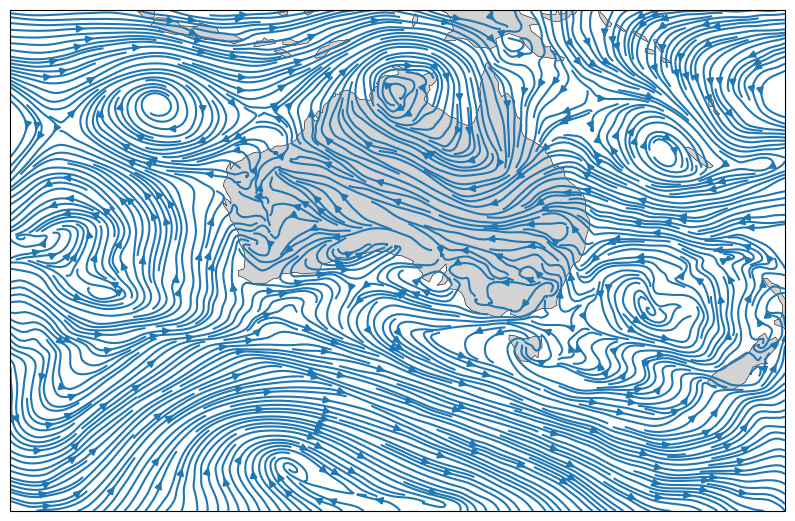

In [ ]:
## Plot the 850hPa wind field to be assigned

u1 = u.reindex(latitude=list(reversed(u.latitude))).sel(
    longitude=slice(80, 180), latitude=slice(-65, 0)
)
v1 = v.reindex(latitude=list(reversed(v.latitude))).sel(
    longitude=slice(80, 180), latitude=slice(-65, 0)
)

fig, ax = plt.subplots(
    1, 1, figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree())
)
plot_extent = [90, 175, -60, -5]
ax.set_extent(plot_extent, crs=ccrs.PlateCarree())
ax.streamplot(
    u1.longitude.values, u1.latitude.values, u1.u.values, v1.v.values, density=5
)
ax.add_feature(LAND, facecolor="lightgrey")
ax.coastlines(linewidths=0.4)

plt.show()

Below is an example of how to assign any gridded field to a SWT. The inputs expected are `u` and `v`-wind fields in xarray dataarray format. The function automatically interpolates the dataset to a 1.5-degree grid. If your data matches the grid provided in the the "SWT_data.nc" file, you can set interpolation=False to avoid this part of the process.

In [ ]:
SWT = assign_grid_to_SWT(
    u.u,
    v.v,
    latname="latitude",
    lonname="longitude",
    cluster_filename= "data/SWT_data.nc",
    quiet=False,
)

Synoptic Weather Type: AM-D


Printing the `assign_grid_to_SWT()` documentation to show its usage and inputs

In [ ]:
print(assign_grid_to_SWT.__doc__)

 Assign a 850hPa wind field to a Australian Synoptic Weather Type
     
    Created by Frans Liqui Lung (Monash University) and Michael A. Barnes (ARC CoE 21st Century Weather, Monash University)
    
    Parameters
    ----------
    
    u : xr.DataArray with shape (latitude,longitude) and dtype float64
        The 850hPa zonal wind field.
    v : xr.DataArray with shape (latitude,longitude) and dtype float64
        The 850hPa meridional wind field.
    
    Options
    -------
    
    latname : str (default: "latitude")
        Name of the latitude variable name in the input u and v DataArrays
    lonname : str (default: "longitude")
        Name of the longitude variable name in the input u and v DataArrays
    cluster_filename : str (default: "SWT_fields/SWT_data.nc")
        Location of the netcdf containing the clustered SWT fields.
    interpolate : bool (default: True)
        If false, does not do any interpolation on the grid. Note: if false, grids must be exactly the same